# 기능 D 굿즈 보존 배경: 조명만 옮기는 방식 비교 (10/28)

15(D1·D2) 결과는 둘 다 쓸 수 없었다. D1(SDXL 인페인팅)은 조명을 바꾸지 않고 굿즈 테두리 밖에 굿즈를 이어 그렸다(studio mug_03 머그 추가, tote_01·tote_03 큰 가방, hoodie_01 사람·후드). D2(IC-Light)는 굿즈 픽셀까지 다시 그려 굿즈 색이 조명색으로 바뀌었다(굿즈 보존 SSIM 0.806, 후드 0.689). 목표는 굿즈의 모양·색·세부는 원본 그대로 두고 조명(밝고 어두운 정도)만 장면에 맞추는 것이다. 아래 후보를 같은 입력으로 비교한다.

| 후보 | 방식 | 근거 |
|---|---|---|
| R0 | 15의 빈 배경 + 원본 굿즈를 마스크 알파로 합성. 조명 변화 없음 (비교 기준) | — |
| R1 | R0 + 조명만 옮김: 굿즈 = 원본 × (흐린 IC-Light 결과 밝기 ÷ 흐린 원본 밝기). 색·세부는 원본 | IC-Light 결과(15 D2)를 조명 정보로만 씀. ComfyUI-IC-Light DetailTransfer 노드(흐린 대상 + 원본 고주파)를 밝기 비율로 바꾼 것이라 실험으로 확인한다 |
| R2 | R1에 IC-Light 색을 비율 k만 섞음: (1−k)·R1 + k·(원본 − 흐린 원본 + 흐린 IC-Light) | 뒤 항이 DetailTransfer "add" 방식 식 `(source − blurred_source) + blurred_target` |
| R1n | R1의 밝기 비율을 굿즈 안 평균으로 나눔(평균 밝기 유지): 밝고 어두운 분포만 옮기고 전체 밝기는 원본 | 10/28 실제 사진 확인: mug_01·desk에서 IC-Light가 머그를 갈색으로 칠해 굿즈 안 비율 평균이 0.56 → R1에서 흰 머그가 회색이 됨. hoodie_02·studio는 평균 1.088로 R1도 자연스러움 |
| R2n | R2와 같고, 밝기 비율과 섞는 IC-Light 항 모두 같은 평균으로 나눔 | R1n과 같음 |
| Y | `yahoo-inc/photo-background-generation`(Apache 2.0, SD2 인페인팅 + ControlNet, 512×512)으로 배경 생성 후 원본 굿즈를 다시 덮어씀. 조명 변화 없음 | Eshratifar et al. CVPRW 2024 "Salient Object-Aware Background Generation": 인페인팅 모델이 물체 경계를 늘리는 현상(object expansion)을 SD2 인페인팅 대비 평균 3.6배 줄였다고 보고 |

- 배경(`bg`): R0·R1·R2·R1n·R2n은 두 가지를 비교한다.
  - `plain`: 15의 빈 배경(`outputs/background_d/backgrounds/`)
  - `ic`: IC-Light 결과의 굿즈 밖 부분. IC-Light가 굿즈와 함께 다시 그린 배경이라 그림자·반사가 들어 있다.
- 흐림 정도 `sigma`(긴 변 1024 기준 px) 8·32, R2 색 비율 `k` 0.1·0.2·0.3은 탐색값이다(근거 문서 없음). 밝기 비율은 0.25~4로 자른다(탐색값).
- 흐림은 마스크 안쪽만으로 계산한다(정규화 합성곱: blur(L·A) ÷ blur(A)). 굿즈 밖 배경 밝기가 굿즈 가장자리로 번지지 않게 하기 위함이다.
- 화면 틀: 15 D2 결과와 같은 비율로 긴 변 1024에 맞추고, 원본·마스크·배경을 같은 틀로 가운데 자른다(IC-Light 데모 `resize_and_center_crop`). 그래서 15의 원본보다 가장자리가 몇 px 잘릴 수 있다.
- Y는 모델 카드 코드(`DiffusionPipeline.from_pretrained(..., custom_pipeline=...)`, `resize_with_padding` 512, 마스크 반전, 20스텝, `controlnet_conditioning_scale` 1.0, `torch.autocast`)를 따른다.
  - 바꾼 점
    - 마스크: 카드의 transparent-background 대신 15의 BiRefNet 마스크
    - seed: 카드 13 대신 15와 같은 0
    - 장면 문구: 15와 같은 문구
  - 현재 diffusers(0.41.0.dev0)에서는 Hub의 사용자 파이프라인 코드를 불러오려면 `trust_remote_code=True`가 필요하다. 저장소 `pipeline.py`가 쓰는 `diffusers.pipelines.controlnet.multicontrolnet`이 `diffusers.models.controlnets.multicontrolnet`으로 옮겨져 있어, 불러오기 전에 옛 경로를 새 모듈로 연결한다.
  - 저장소 `requirements.txt`는 diffusers 0.27.2 기준이다. 현재 버전에서 그대로 도는지는 이 노트북 실행으로 확인한다. 별도 프로세스에서 돌려 실패해도 이 커널은 멈추지 않는다.
- 15의 D1·D2도 같은 틀로 잘라 지표·그림에 함께 넣는다(다시 생성하지 않음).
- 지표 (굿즈 마스크를 4px 줄인 영역)
  - 굿즈 구조 보존: 원본 대비 회색조 SSIM (`prod_ssim`)
  - 굿즈 색 유지: Lab 색도 차이 평균 √(Δa*² + Δb*²) (`prod_dC`, 작을수록 원본 색)
  - 조명 반영량: Lab 밝기 차이 평균 |ΔL*| (`prod_dL`, 0이면 조명 변화 없음)
  - 장면 반영: 결과 이미지와 장면 문구의 CLIP 유사도 (`scene_sim`)
  - 육안: 장면별 비교 그림 (굿즈 이어 그리기, 경계, 조명이 어울리는지)
- 기록 (`outputs/background_relight/`)
  - `r_config.json`: 후보별 설정 전문, 입력 목록, 패키지 버전, GPU
  - `r_records.csv`: 이미지 1장마다 방식·굿즈·장면·설정·시간·최대 VRAM·오류
  - `r_runs.csv`: 단계마다 시작·종료 시각, 모델 로드 시간, 전체 시간, 장수
  - `r_scored.csv`, `r_summary.csv`, `r_scores.png`, `r_color_vs_light.png`
  - `r_grid_<장면>.png`(주요 후보), `r_grid_<장면>_<배경>.png`(R1·R2), `r_grid_<장면>_norm_<배경>.png`(R1n·R2n)
  - `y_raw/`: Y 모델의 512×512 원출력
- 진행 출력: 단계마다 `[시각 | 경과 | VRAM] 내용`을 한 줄씩 바로 출력한다(모델 로드 시작·끝, 몇 번째/전체).
- 실행 순서: 15를 끝낸 뒤, 위에서부터 차례로. 다시 실행하면 오류 없이 만든 이미지는 건너뛴다.
- 예상(추정): R 33가지 × 33장 = 1,089장. 후처리라 장당 1~2초(클라우드 CPU 시험 기준, 여기서는 흐림을 GPU로 계산). PNG로 약 1.3GB. Y는 첫 실행 때 safetensors 약 6.6GB를 받는다(unet 3.46GB, controlnet 1.46GB, text_encoder 1.36GB, vae 335MB, Hub 파일 목록 기준).
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 설정

In [1]:
import gc
import importlib.metadata
import json
import os
import platform
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageFilter

ROOT = Path('..')
D_DIR = ROOT / 'outputs' / 'background_d'
OUT_DIR = ROOT / 'outputs' / 'background_relight'
OUT_DIR.mkdir(parents=True, exist_ok=True)
REC_CSV = OUT_DIR / 'r_records.csv'
RUNS_CSV = OUT_DIR / 'r_runs.csv'

GOODS_DIR = ROOT / 'data' / 'raw' / 'goods'
GOODS = pd.read_csv(GOODS_DIR / 'goods_sources.csv', keep_default_na=False)
GOODS = GOODS[(GOODS.error == '') & GOODS.file.map(lambda f: (GOODS_DIR / f).exists())].reset_index(drop=True)
KIND_EN = {'tshirt': 't-shirt', 'hoodie': 'hoodie', 'tote': 'tote bag', 'mug': 'mug'}
# 15와 같은 장면 문구·입력 크기
SCENES = {
    'desk': 'on a wooden desk next to a game controller and small figures, warm desk lamp light, cozy room',
    'studio': 'on a pastel color studio backdrop, soft shadow, clean background',
    'cafe': 'on a cafe table by the window, morning sunlight, shallow depth of field',
}
MAX_SIDE = 1024
SEED = 0

# R 후보 (탐색값)
SIGMAS = [8, 32]
COLOR_K = [0.1, 0.2, 0.3]
RATIO_CLIP = (0.25, 4.0)
BGS = ['plain', 'ic']
VARIANTS = [dict(method='R0', bg='plain', sigma=None, k=None)]
VARIANTS += [dict(method=f'R1_s{s}_{b}', bg=b, sigma=s, k=None) for b in BGS for s in SIGMAS]
VARIANTS += [dict(method=f'R2_s{s}_k{k}_{b}', bg=b, sigma=s, k=k) for b in BGS for s in SIGMAS for k in COLOR_K]
# 평균 밝기 유지(norm): 비율을 굿즈 안 평균으로 나눔
VARIANTS = [dict(v, norm=False) for v in VARIANTS]
VARIANTS += [dict(v, method=v['method'].replace('R1_', 'R1n_').replace('R2_', 'R2n_'), norm=True)
             for v in VARIANTS if v['method'].startswith(('R1_', 'R2_'))]

Y_REPO = 'yahoo-inc/photo-background-generation'
# 모델 카드 값: 512 입력, 20스텝, ControlNet 1.0, guess_mode False
Y_ARGS = dict(size=512, steps=20, cond_scale=1.0, guess_mode=False)


def scene_prompt(kind, scene):
    return f'product photography of a {KIND_EN[kind]} {SCENES[scene]}'


def out_name(method, name, scene):
    return f'{method}__{Path(name).stem}__{scene}.png'


def load_goods(name):
    im = Image.open(GOODS_DIR / name).convert('RGB')
    s = MAX_SIDE / max(im.size)
    return im.resize((int(round(im.width * s / 8)) * 8, int(round(im.height * s / 8)) * 8), Image.LANCZOS)


def center_crop(im, w, h):
    # IC-Light 데모 resize_and_center_crop과 같은 방식 (PIL 이미지용)
    s = max(w / im.width, h / im.height)
    rw, rh = int(round(im.width * s)), int(round(im.height * s))
    im = im.resize((rw, rh), Image.LANCZOS)
    return im.crop(((rw - w) / 2, (rh - h) / 2, (rw + w) / 2, (rh + h) / 2))


def frame(name, scene):
    # 15 D2 결과와 같은 비율, 긴 변 1024
    w, h = Image.open(D_DIR / out_name('D2', name, scene)).size
    s = MAX_SIDE / max(w, h)
    return int(round(w * s / 8)) * 8, int(round(h * s / 8)) * 8


def inputs(name, scene):
    w, h = frame(name, scene)
    goods = np.asarray(center_crop(load_goods(name), w, h), dtype=np.float32) / 255
    mask = Image.open(D_DIR / 'masks' / f'{Path(name).stem}.png').convert('L')
    alpha = np.asarray(center_crop(mask.resize(load_goods(name).size, Image.BILINEAR), w, h), dtype=np.float32) / 255
    bg = np.asarray(center_crop(Image.open(D_DIR / 'backgrounds' / f'{scene}.png').convert('RGB'), w, h), dtype=np.float32) / 255
    ic = np.asarray(Image.open(D_DIR / out_name('D2', name, scene)).convert('RGB').resize((w, h), Image.LANCZOS), dtype=np.float32) / 255
    return goods, alpha, bg, ic


need = [D_DIR / 'masks.csv', *[D_DIR / 'backgrounds' / f'{sc}.png' for sc in SCENES],
        *[D_DIR / out_name('D2', g, sc) for g in GOODS.file for sc in SCENES]]
miss = [str(p) for p in need if not p.exists()]
assert not miss, f'15 결과가 없음 → 15를 먼저 끝까지 실행: {miss[:3]}'
print('굿즈', len(GOODS), '장 × 장면', len(SCENES), '| R 후보', len(VARIANTS), '가지 + Y')

recs = {x['file']: x for x in pd.read_csv(REC_CSV, keep_default_na=False).to_dict('records')} if REC_CSV.exists() else {}


def done(f):
    return recs.get(f, {}).get('error', 'x') == '' and (OUT_DIR / f).exists()


def save_rec(rec):
    recs[rec['file']] = rec
    pd.DataFrame(list(recs.values())).to_csv(REC_CSV, index=False, encoding='utf-8-sig')


def append_csv(path, rec):
    pd.DataFrame([rec]).to_csv(path, mode='a', header=not path.exists(), index=False, encoding='utf-8-sig')


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


# 멈춤 여부를 바로 알 수 있게 단계마다 시각·단계 시작 후 경과·VRAM(현재/최대)을 함께 출력
def log(msg, t_start=None):
    el = ''
    if t_start is not None:
        m, sec = divmod(int(time.perf_counter() - t_start), 60)
        el = f' | 경과 {m // 60:d}:{m % 60:02d}:{sec:02d}'
    vr = ''
    if torch.cuda.is_available():
        vr = f' | VRAM {torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)'
    print(f'[{time.strftime("%H:%M:%S")}{el}{vr}] {msg}', flush=True)

굿즈 11 장 × 장면 3 | R 후보 33 가지 + Y


## R 조명만 옮기기 (후처리)

In [2]:
def gblur(x, sigma):
    # 분리형 가우시안 (x: H×W×C float). 반사 패딩
    r = int(3 * sigma)
    k = torch.exp(-(torch.arange(-r, r + 1, dtype=torch.float32) ** 2) / (2 * sigma ** 2))
    k = k / k.sum()
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    t = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))[:, None].to(dev)
    k = k.to(dev)
    t = F.conv2d(F.pad(t, (r, r, 0, 0), mode='reflect'), k.view(1, 1, 1, -1))
    t = F.conv2d(F.pad(t, (0, 0, r, r), mode='reflect'), k.view(1, 1, -1, 1))
    return t[:, 0].cpu().numpy().transpose(1, 2, 0)


def masked_blur(x, a, sigma):
    # 굿즈 안쪽 값만으로 흐림 (정규화 합성곱): 배경 밝기가 굿즈 가장자리로 번지지 않게
    return gblur(x * a[..., None], sigma) / np.maximum(gblur(a[..., None], sigma), 1e-4)


def luma(x):
    return (x @ np.array([0.299, 0.587, 0.114], dtype=np.float32))[..., None]


def relight(goods, alpha, ic, sigma, k, norm=False):
    lo = masked_blur(luma(goods), alpha, sigma)
    li = masked_blur(luma(ic), alpha, sigma)
    ratio = (li + 1e-3) / (lo + 1e-3)
    # norm: 굿즈 안(알파 가중) 평균 비율로 나눠 전체 밝기는 원본 유지
    mean = float((ratio[..., 0] * alpha).sum() / max(alpha.sum(), 1e-6)) if norm else 1.0
    out = goods * np.clip(ratio / mean, *RATIO_CLIP)
    if k:
        colored = goods - masked_blur(goods, alpha, sigma) + masked_blur(ic, alpha, sigma) / mean
        out = (1 - k) * out + k * colored
    return out.clip(0, 1)


todo_r = [(g, sc, v) for g in GOODS.itertuples() for sc in SCENES for v in VARIANTS if not done(out_name(v['method'], g.file, sc))]
print('R', len(todo_r), '/', len(GOODS) * len(SCENES) * len(VARIANTS), '장')
if todo_r:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    cache = {}
    for i, (g, sc, v) in enumerate(todo_r, 1):
        f = out_name(v['method'], g.file, sc)
        rec = dict(file=f, method=v['method'], goods=g.file, kind=g.kind, scene=sc,
                   params=json.dumps(dict(v, ratio_clip=RATIO_CLIP, frame=frame(g.file, sc))), error='')
        try:
            t0 = time.perf_counter()
            if (g.file, sc) not in cache:
                cache = {(g.file, sc): inputs(g.file, sc)}
            goods, alpha, bg, ic = cache[(g.file, sc)]
            fg = goods if v['sigma'] is None else relight(goods, alpha, ic, v['sigma'], v['k'], v['norm'])
            base = bg if v['bg'] == 'plain' else ic
            a = alpha[..., None]
            Image.fromarray(((fg * a + base * (1 - a)) * 255).round().clip(0, 255).astype(np.uint8)).save(OUT_DIR / f)
            rec['sec'] = round(time.perf_counter() - t0, 2)
        except Exception as e:
            rec['error'] = f'{type(e).__name__}: {e}'[:300]
        save_rec(rec)
        if i % len(VARIANTS) == 0 or rec['error'] or i == len(todo_r):
            log(f'R {i}/{len(todo_r)} {f} {rec.get("sec")}초 {rec["error"][:100]}', t_all)
    append_csv(RUNS_CSV, dict(stage='R (후처리)', started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'),
                              sec_total=round(time.perf_counter() - t_all, 1), n_new=len(todo_r), load_sec=0, peak_vram_gb=0))

R 1089 / 1089 장
[09:08:28 | 경과 0:00:09 | VRAM 0.0GB (최대 0.0GB)] R 33/1089 R2n_s32_k0.3_ic__mug_01__desk.png 0.3초 
[09:08:38 | 경과 0:00:19 | VRAM 0.0GB (최대 0.0GB)] R 66/1089 R2n_s32_k0.3_ic__mug_01__studio.png 0.38초 
[09:08:49 | 경과 0:00:30 | VRAM 0.0GB (최대 0.0GB)] R 99/1089 R2n_s32_k0.3_ic__mug_01__cafe.png 0.34초 
[09:08:56 | 경과 0:00:38 | VRAM 0.0GB (최대 0.0GB)] R 132/1089 R2n_s32_k0.3_ic__mug_02__desk.png 0.24초 
[09:09:03 | 경과 0:00:45 | VRAM 0.0GB (최대 0.0GB)] R 165/1089 R2n_s32_k0.3_ic__mug_02__studio.png 0.22초 
[09:09:10 | 경과 0:00:51 | VRAM 0.0GB (최대 0.0GB)] R 198/1089 R2n_s32_k0.3_ic__mug_02__cafe.png 0.2초 
[09:09:17 | 경과 0:00:59 | VRAM 0.0GB (최대 0.0GB)] R 231/1089 R2n_s32_k0.3_ic__mug_03__desk.png 0.21초 
[09:09:24 | 경과 0:01:06 | VRAM 0.0GB (최대 0.0GB)] R 264/1089 R2n_s32_k0.3_ic__mug_03__studio.png 0.21초 
[09:09:31 | 경과 0:01:13 | VRAM 0.0GB (최대 0.0GB)] R 297/1089 R2n_s32_k0.3_ic__mug_03__cafe.png 0.21초 
[09:09:38 | 경과 0:01:20 | VRAM 0.0GB (최대 0.0GB)] R 330/1089 R2n_s32_k0.3_ic__mug_04_

## Y 이어 그리기를 줄이는 배경 생성 모델 (별도 프로세스)

In [3]:
CHILD_Y = r"""
import csv, json, os, sys, time
import numpy as np
import torch
from PIL import Image, ImageOps

a = json.loads(sys.stdin.read())
T0 = time.perf_counter()


def log(msg):
    m, s = divmod(int(time.perf_counter() - T0), 60)
    vr = f' | VRAM {torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)'
    print(f'[{time.strftime("%H:%M:%S")} | 경과 {m // 60:d}:{m % 60:02d}:{s:02d}{vr}] {msg}', flush=True)


def resize_with_padding(img, expected_size):
    # 모델 카드 코드 그대로
    img.thumbnail((expected_size[0], expected_size[1]))
    delta_width = expected_size[0] - img.size[0]
    delta_height = expected_size[1] - img.size[1]
    pad_width = delta_width // 2
    pad_height = delta_height // 2
    padding = (pad_width, pad_height, delta_width - pad_width, delta_height - pad_height)
    return ImageOps.expand(img, padding), padding


# 저장소 pipeline.py(diffusers 0.27 기준)의 옛 경로 → 현재 diffusers의 같은 모듈
import diffusers.models.controlnets.multicontrolnet as _mc
sys.modules.setdefault('diffusers.pipelines.controlnet.multicontrolnet', _mc)
from diffusers import DiffusionPipeline

log('Y 로드 시작 (첫 실행이면 다운로드 포함)')
pipe = DiffusionPipeline.from_pretrained(a['repo'], custom_pipeline=a['repo'], trust_remote_code=True).to('cuda')
pipe.set_progress_bar_config(disable=True)
load_sec = round(time.perf_counter() - T0, 1)
log(f'Y 로드 끝 {load_sec}초 | {type(pipe).__name__}')
FIELDS = ['file', 'method', 'goods', 'kind', 'scene', 'params', 'sec', 'peak_vram_gb', 'load_sec', 'error']
S = a['size']
for i, t in enumerate(a['tasks'], 1):
    rec = {k: t.get(k, '') for k in FIELDS}
    rec['load_sec'] = load_sec
    try:
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        goods = Image.open(t['goods_path']).convert('RGB')
        fg = Image.open(t['mask_path']).convert('L')
        img, pad = resize_with_padding(goods.copy(), (S, S))
        m, _ = resize_with_padding(fg.copy(), (S, S))
        mask = ImageOps.invert(m)
        g = torch.Generator(device='cuda').manual_seed(a['seed'])
        with torch.autocast('cuda'):
            out = pipe(prompt=t['prompt'], image=img, mask_image=mask, control_image=mask, num_images_per_prompt=1, generator=g,
                       num_inference_steps=a['steps'], guess_mode=a['guess_mode'],
                       controlnet_conditioning_scale=a['cond_scale']).images[0]
        out.save(t['raw_out'])
        # 패딩을 걷어내고 원래 틀로 키운 뒤 원본 굿즈를 마스크 알파로 다시 덮어씀
        box = (pad[0], pad[1], S - pad[2], S - pad[3])
        big = np.asarray(out.crop(box).resize(goods.size, Image.LANCZOS), dtype=np.float32)
        al = np.asarray(fg, dtype=np.float32)[..., None] / 255
        res = np.asarray(goods, dtype=np.float32) * al + big * (1 - al)
        Image.fromarray(res.round().clip(0, 255).astype(np.uint8)).save(t['out'])
        rec['sec'] = round(time.perf_counter() - t1, 2)
        rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    new = not os.path.exists(a['csv'])
    with open(a['csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow(rec)
    log(f"Y {i}/{len(a['tasks'])} {t['file']} {rec.get('sec')}초 {rec['error'][:100]}")
"""

todo_y = [(g, sc) for g in GOODS.itertuples() for sc in SCENES if not done(out_name('Y', g.file, sc))]
print('Y', len(todo_y), '장')
if todo_y:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    (OUT_DIR / 'y_raw').mkdir(exist_ok=True)
    (OUT_DIR / '_in').mkdir(exist_ok=True)
    tasks = []
    for g, sc in todo_y:
        goods, alpha, _, _ = inputs(g.file, sc)
        gp, mp = OUT_DIR / '_in' / f'{Path(g.file).stem}__{sc}.png', OUT_DIR / '_in' / f'{Path(g.file).stem}__{sc}_mask.png'
        Image.fromarray((goods * 255).round().astype(np.uint8)).save(gp)
        Image.fromarray((alpha * 255).round().astype(np.uint8)).save(mp)
        f = out_name('Y', g.file, sc)
        tasks.append(dict(file=f, method='Y', goods=g.file, kind=g.kind, scene=sc, prompt=scene_prompt(g.kind, sc),
                          goods_path=str(gp.resolve()), mask_path=str(mp.resolve()), out=str((OUT_DIR / f).resolve()),
                          raw_out=str((OUT_DIR / 'y_raw' / f).resolve()),
                          params=json.dumps(dict(Y_ARGS, repo=Y_REPO, seed=SEED, prompt=scene_prompt(g.kind, sc), frame=frame(g.file, sc),
                                                 mask='BiRefNet (15), inverted', paste_back='original goods by mask alpha'))))
    Y_TMP = OUT_DIR / 'y_child.csv'
    Y_TMP.unlink(missing_ok=True)
    proc = subprocess.Popen([sys.executable, '-c', CHILD_Y], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                            env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    proc.stdin.write(json.dumps(dict(repo=Y_REPO, seed=SEED, csv=str(Y_TMP.resolve()), tasks=tasks, **Y_ARGS)))
    proc.stdin.close()
    # 진행 상황을 셀 출력에 바로 보여 줌 (다운로드 진행 막대 포함)
    for line in proc.stdout:
        print(line, end='', flush=True)
    rc = proc.wait()
    got = pd.read_csv(Y_TMP, keep_default_na=False).to_dict('records') if Y_TMP.exists() else []
    for x in got:
        save_rec(x)
    got_files = {x['file'] for x in got}
    for t in tasks:
        if t['file'] not in got_files:
            save_rec({k: t[k] for k in ['file', 'method', 'goods', 'kind', 'scene', 'params']} | dict(error=f'프로세스 종료 코드 {rc}'))
    peaks = [float(x['peak_vram_gb']) for x in got if x['peak_vram_gb'] != '']
    append_csv(RUNS_CSV, dict(stage='Y (photo-background-generation, 별도 프로세스)', started=started,
                              ended=time.strftime('%Y-%m-%d %H:%M:%S'), sec_total=round(time.perf_counter() - t_all, 1),
                              n_new=sum(x['error'] == '' for x in got), load_sec=got[0]['load_sec'] if got else None,
                              peak_vram_gb=max(peaks) if peaks else None))
    log(f'Y 종료 코드 {rc} | 새로 만든 장수 {sum(x["error"] == "" for x in got)}', t_all)

config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), goods=GOODS[['file', 'kind', 'site', 'page']].to_dict('records'), scenes=SCENES,
    seed=SEED, max_side=MAX_SIDE, inputs_from=str(D_DIR), variants=VARIANTS, ratio_clip=RATIO_CLIP,
    Y=dict(repo=Y_REPO, **Y_ARGS, trust_remote_code=True, mask='BiRefNet (15)'),
    versions={p: pkg_version(p) for p in ['torch', 'torchvision', 'diffusers', 'transformers', 'accelerate', 'safetensors', 'pillow', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'r_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1, default=str), encoding='utf-8')
rr = pd.read_csv(REC_CSV, keep_default_na=False)
print('기록', len(rr), '장 | 오류', (rr.error != '').sum())
display(rr[rr.error != ''][['file', 'error']].head(10))

Y 33 장
Multiple distributions found for package optimum. Picked distribution: optimum
W1030 09:13:14.055000 17748 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1030 09:13:14.161000 17748 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
[09:13:18 | 경과 0:00:30 | VRAM 0.0GB (최대 0.0GB)] Y 로드 시작 (첫 실행이면 다운로드 포함)
c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses 

,file,error


## 지표

In [4]:
def _box(x, r=3):
    # 7×7 평균 필터 (누적합), 15와 같음
    p = np.pad(x, r + 1, mode='edge')
    c = p.cumsum(0).cumsum(1)
    k = 2 * r + 1
    return (c[k:, k:] - c[:-k, k:] - c[k:, :-k] + c[:-k, :-k])[:x.shape[0], :x.shape[1]] / (k * k)


def ssim_map(a, b):
    # 회색조 SSIM (Wang et al. 2004 상수, 7×7 평균 창), 입력 0~1
    # 누적합 정밀도 때문에 float64 (float32면 1024px에서 값이 무너짐)
    a, b = luma(a)[..., 0].astype(np.float64) * 255, luma(b)[..., 0].astype(np.float64) * 255
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    ma, mb = _box(a), _box(b)
    va, vb, cov = _box(a * a) - ma ** 2, _box(b * b) - mb ** 2, _box(a * b) - ma * mb
    return ((2 * ma * mb + c1) * (2 * cov + c2)) / ((ma ** 2 + mb ** 2 + c1) * (va + vb + c2))


def to_lab(x):
    # sRGB(D65) → CIE Lab
    c = np.where(x > 0.04045, ((x + 0.055) / 1.055) ** 2.4, x / 12.92)
    m = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
    xyz = c @ m.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], -1)


from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def unit(e):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    e = (e.pooler_output if hasattr(e, 'pooler_output') else e).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


with torch.no_grad():
    SCENE_E = dict(zip(SCENES, unit(clip.get_text_features(**clip_proc(text=list(SCENES.values()), return_tensors='pt',
                                                                         padding=True, truncation=True).to('cuda')))))

# 15의 D1·D2도 같은 틀로 잘라 함께 잼 (다시 생성하지 않음)
dd = pd.read_csv(D_DIR / 'd_records.csv', keep_default_na=False)
dd = dd[dd.error == ''].assign(src='15')
rr = pd.read_csv(REC_CSV, keep_default_na=False)
rr = rr[rr.error == ''].assign(src='16')
allr = pd.concat([dd[['file', 'method', 'goods', 'kind', 'scene', 'sec', 'src']], rr[['file', 'method', 'goods', 'kind', 'scene', 'sec', 'src']]],
                 ignore_index=True)
rows, t_all = [], time.perf_counter()
log(f'지표 시작 {len(allr)}장', t_all)
for i, r in enumerate(allr.itertuples(), 1):
    goods, alpha, _, _ = inputs(r.goods, r.scene)
    w, h = goods.shape[1], goods.shape[0]
    im = Image.open((D_DIR if r.src == '15' else OUT_DIR) / r.file).convert('RGB')
    im = center_crop(im, w, h) if r.method == 'D1' else im.resize((w, h), Image.LANCZOS)
    out = np.asarray(im, dtype=np.float32) / 255
    prod = np.asarray(Image.fromarray((alpha > 0.5).astype(np.uint8) * 255).filter(ImageFilter.MinFilter(9))) > 0
    lo, lr = to_lab(goods)[prod], to_lab(out)[prod]
    with torch.no_grad():
        e = unit(clip.get_image_features(**clip_proc(images=[im], return_tensors='pt').to('cuda')))[0]
    rows.append(dict(file=r.file, method=r.method, goods=r.goods, kind=r.kind, scene=r.scene, src=r.src,
                     sec=float(r.sec) if r.sec != '' else np.nan, prod_ssim=float(ssim_map(goods, out)[prod].mean()),
                     prod_dC=float(np.linalg.norm(lr[:, 1:] - lo[:, 1:], axis=1).mean()), prod_dL=float(np.abs(lr[:, 0] - lo[:, 0]).mean()),
                     scene_sim=float(e @ SCENE_E[r.scene])))
    if i % 66 == 0 or i == len(allr):
        log(f'지표 {i}/{len(allr)}', t_all)
ds = pd.DataFrame(rows)
ds.to_csv(OUT_DIR / 'r_scored.csv', index=False, encoding='utf-8-sig')
ORDER = ['D1', 'D2', 'R0'] + [v['method'] for v in VARIANTS[1:]] + ['Y']
ORDER = [m for m in ORDER if m in set(ds.method)]
summ = ds.groupby('method')[['prod_ssim', 'prod_dC', 'prod_dL', 'scene_sim', 'sec']].agg(['mean', 'std']).reindex(ORDER)
summ.to_csv(OUT_DIR / 'r_summary.csv', encoding='utf-8-sig')
display(summ.round(3))
print('종류별 굿즈 색 차이(prod_dC)')
display(ds.pivot_table(index='method', columns='kind', values='prod_dC').reindex(ORDER).round(2))
del clip
gc.collect()
torch.cuda.empty_cache()

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1030 09:15:59.648000 42752 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1030 09:15:59.734000 42752 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 22078.20it/s]


[09:16:04 | 경과 0:00:00 | VRAM 0.6GB (최대 0.6GB)] 지표 시작 1188장
[09:17:22 | 경과 0:01:17 | VRAM 0.6GB (최대 0.6GB)] 지표 66/1188
[09:18:46 | 경과 0:02:42 | VRAM 0.6GB (최대 0.6GB)] 지표 132/1188
[09:19:57 | 경과 0:03:53 | VRAM 0.6GB (최대 0.6GB)] 지표 198/1188
[09:20:53 | 경과 0:04:49 | VRAM 0.6GB (최대 0.6GB)] 지표 264/1188
[09:22:10 | 경과 0:06:06 | VRAM 0.6GB (최대 0.6GB)] 지표 330/1188
[09:23:25 | 경과 0:07:20 | VRAM 0.6GB (최대 0.6GB)] 지표 396/1188
[09:24:37 | 경과 0:08:32 | VRAM 0.6GB (최대 0.6GB)] 지표 462/1188
[09:25:33 | 경과 0:09:29 | VRAM 0.6GB (최대 0.6GB)] 지표 528/1188
[09:26:30 | 경과 0:10:25 | VRAM 0.6GB (최대 0.6GB)] 지표 594/1188
[09:27:28 | 경과 0:11:23 | VRAM 0.6GB (최대 0.6GB)] 지표 660/1188
[09:28:57 | 경과 0:12:53 | VRAM 0.6GB (최대 0.6GB)] 지표 726/1188
[09:30:28 | 경과 0:14:23 | VRAM 0.6GB (최대 0.6GB)] 지표 792/1188
[09:31:55 | 경과 0:15:50 | VRAM 0.6GB (최대 0.6GB)] 지표 858/1188
[09:32:59 | 경과 0:16:54 | VRAM 0.6GB (최대 0.6GB)] 지표 924/1188
[09:34:21 | 경과 0:18:17 | VRAM 0.6GB (최대 0.6GB)] 지표 990/1188
[09:36:03 | 경과 0:19:59 | VRAM 0.6GB (최대 0

prod_ssim        prod_dC         prod_dL        scene_sim  \
                        mean    std    mean     std    mean    std      mean   
method                                                                         
D1                     0.999  0.001   0.225   0.095   0.131  0.077     0.254   
D2                     0.842  0.080  30.967  10.483  10.428  7.221     0.273   
R0                     1.000  0.000   0.083   0.068   0.084  0.077     0.262   
R1_s8_plain            0.957  0.039   0.805   1.362  10.000  7.275     0.265   
R1_s32_plain           0.975  0.035   0.777   1.354   9.665  7.471     0.264   
R1_s8_ic               0.957  0.039   0.825   1.374   9.992  7.257     0.262   
R1_s32_ic              0.975  0.035   0.796   1.367   9.660  7.449     0.262   
R2_s8_k0.1_plain       0.958  0.038   3.248   1.455  10.069  7.327     0.266   
R2_s8_k0.2_plain       0.958  0.038   6.083   2.094  10.126  7.372     0.268   
R2_s8_k0.3_plain       0.958  0.038   9.007   2.966  10.172  7.409     0.270   
R2_s32_k0.1_plain      0.975  0.035   3.225   1.451   9.732  7.527     0.264   
R2_s32_k0.2_plain      0.975  0.035   6.058   2.091   9.788  7.575     0.265   
R2_s32_k0.3_plain      0.976  0.034   8.973   2.967   9.833  7.614     0.268   
R2_s8_k0.1_ic          0.958  0.038   3.299   1.482  10.061  7.309     0.262   
R2_s8_k0.2_ic          0.958  0.038   6.136   2.124  10.118  7.354     0.264   
R2_s8_k0.3_ic          0.958  0.038   9.060   2.997  10.163  7.390     0.266   
R2_s32_k0.1_ic         0.975  0.035   3.276   1.477   9.726  7.505     0.261   
R2_s32_k0.2_ic         0.976  0.035   6.110   2.122   9.782  7.553     0.262   
R2_s32_k0.3_ic         0.976  0.034   9.026   2.998   9.826  7.592     0.264   
R1n_s8_plain           0.973  0.024   0.375   0.294   4.249  2.590     0.265   
R1n_s32_plain          0.993  0.009   0.300   0.209   3.338  2.373     0.264   
R1n_s8_ic              0.973  0.024   0.394   0.282   4.251  2.597     0.262   
R1n_s32_ic             0.993  0.009   0.322   0.196   3.336  2.378     0.261   
R2n_s8_k0.1_plain      0.973  0.024   3.092   1.108   4.265  2.590     0.266   
R2n_s8_k0.2_plain      0.973  0.024   6.101   2.229   4.274  2.589     0.268   
R2n_s8_k0.3_plain      0.974  0.023   9.155   3.375   4.277  2.585     0.270   
R2n_s32_k0.1_plain     0.993  0.009   3.076   1.104   3.355  2.373     0.264   
R2n_s32_k0.2_plain     0.993  0.008   6.094   2.240   3.367  2.372     0.266   
R2n_s32_k0.3_plain     0.993  0.008   9.152   3.415   3.376  2.371     0.268   
R2n_s8_k0.1_ic         0.973  0.024   3.141   1.127   4.265  2.598     0.262   
R2n_s8_k0.2_ic         0.973  0.024   6.152   2.248   4.272  2.597     0.264   
R2n_s8_k0.3_ic         0.974  0.023   9.207   3.396   4.273  2.594     0.266   
R2n_s32_k0.1_ic        0.993  0.009   3.126   1.123   3.350  2.378     0.261   
R2n_s32_k0.2_ic        0.993  0.008   6.146   2.260   3.359  2.379     0.263   
R2n_s32_k0.3_ic        0.993  0.008   9.204   3.436   3.366  2.379     0.264   
Y                      1.000  0.000   0.000   0.000   0.000  0.000     0.247   

                             sec         
                      std   mean    std  
method                                   
D1                  0.027  8.250  1.297  
D2                  0.032  5.689  0.800  
R0                  0.031  0.623  0.231  
R1_s8_plain         0.029  0.149  0.055  
R1_s32_plain        0.030  0.148  0.025  
R1_s8_ic            0.030  0.144  0.022  
R1_s32_ic           0.030  0.162  0.038  
R2_s8_k0.1_plain    0.030  0.219  0.046  
R2_s8_k0.2_plain    0.031  0.214  0.041  
R2_s8_k0.3_plain    0.032  0.214  0.033  
R2_s32_k0.1_plain   0.031  0.240  0.063  
R2_s32_k0.2_plain   0.032  0.222  0.040  
R2_s32_k0.3_plain   0.033  0.229  0.045  
R2_s8_k0.1_ic       0.030  0.212  0.038  
R2_s8_k0.2_ic       0.031  0.215  0.040  
R2_s8_k0.3_ic       0.032  0.221  0.049  
R2_s32_k0.1_ic      0.031  0.233  0.048  
R2_s32_k0.2_ic      0.032  0.225  0.044  
R2_s32_k0.3_ic  

종류별 굿즈 색 차이(prod_dC)


kind,hoodie,mug,tote,tshirt
method,,,,
D1,0.29,0.26,0.21,0.12
D2,31.68,30.77,37.59,20.72
R0,0.07,0.10,0.07,0.08
R1_s8_plain,1.08,0.46,1.48,0.21
R1_s32_plain,1.04,0.45,1.41,0.21
R1_s8_ic,1.07,0.47,1.54,0.22
R1_s32_ic,1.03,0.46,1.46,0.22
R2_s8_k0.1_plain,3.04,3.02,4.49,2.04
R2_s8_k0.2_plain,6.03,5.83,7.87,3.96


## 시각화

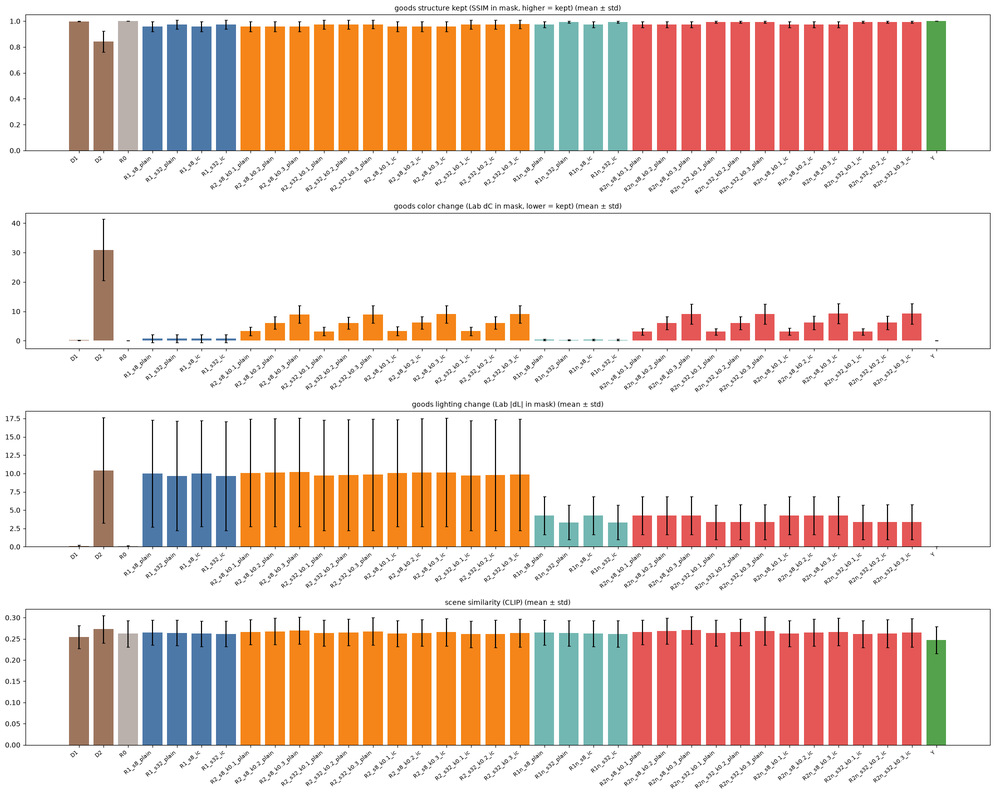

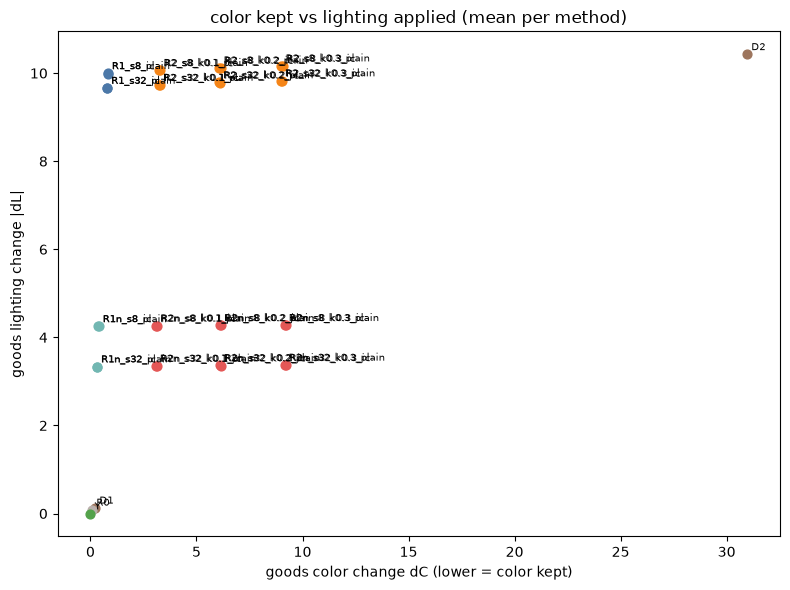

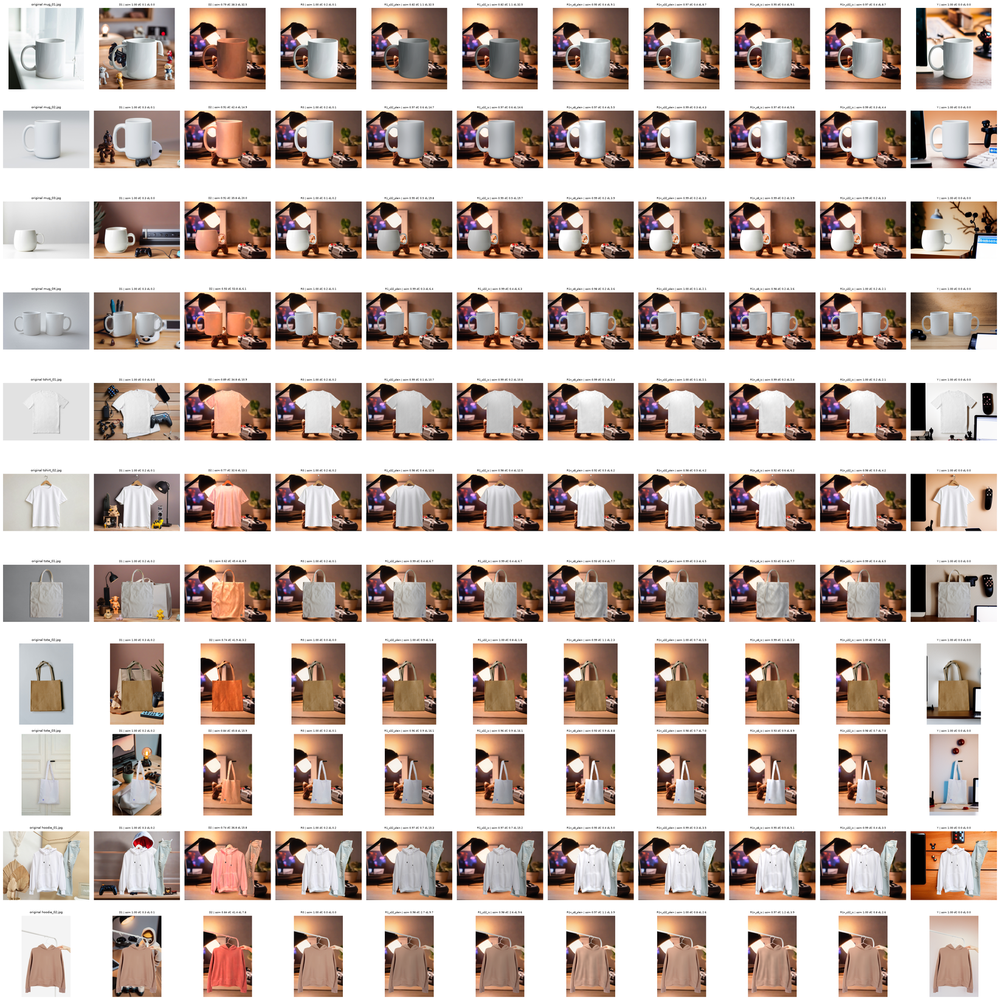

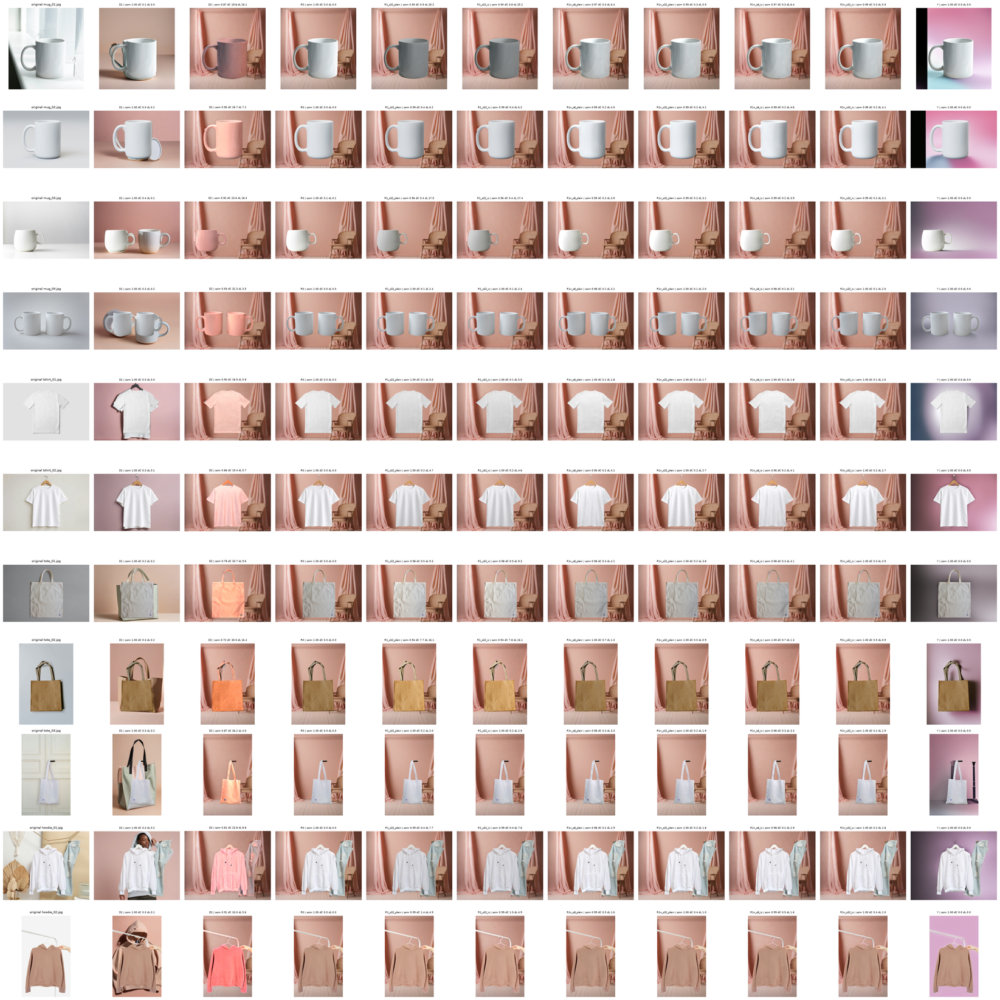

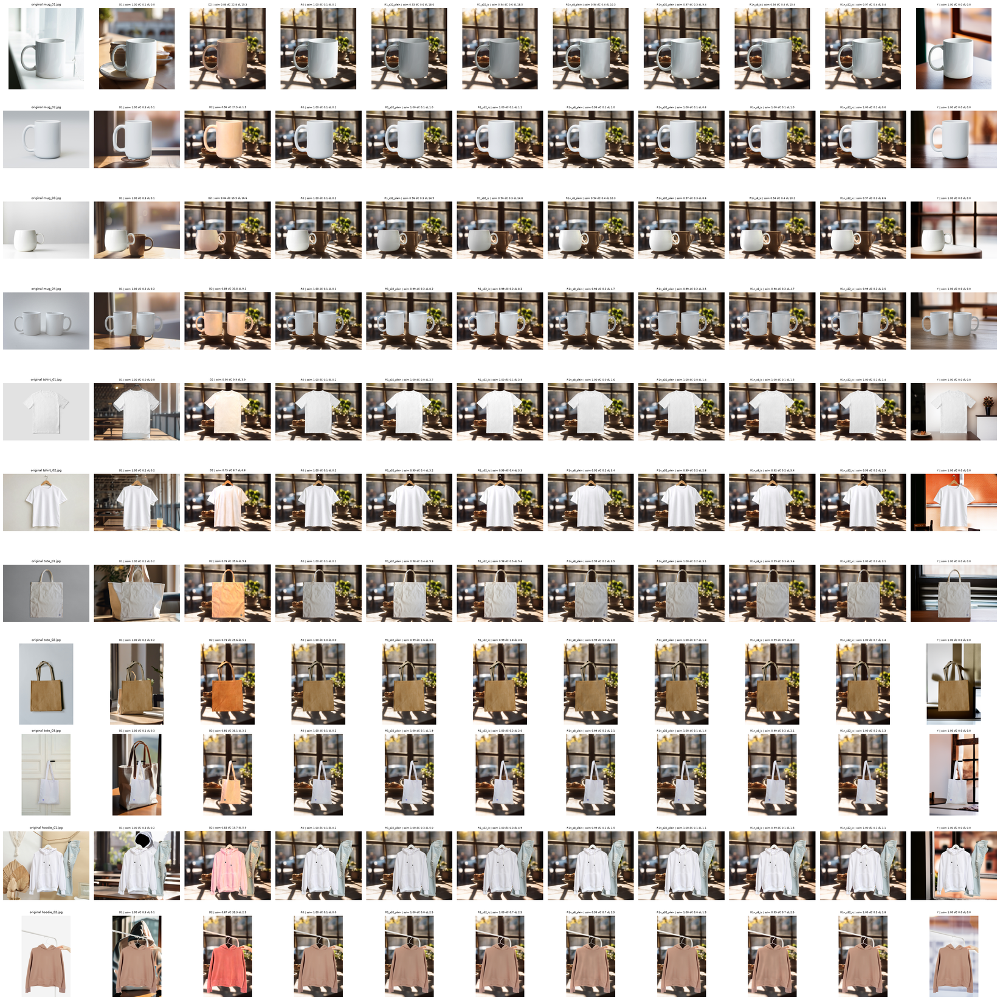

...

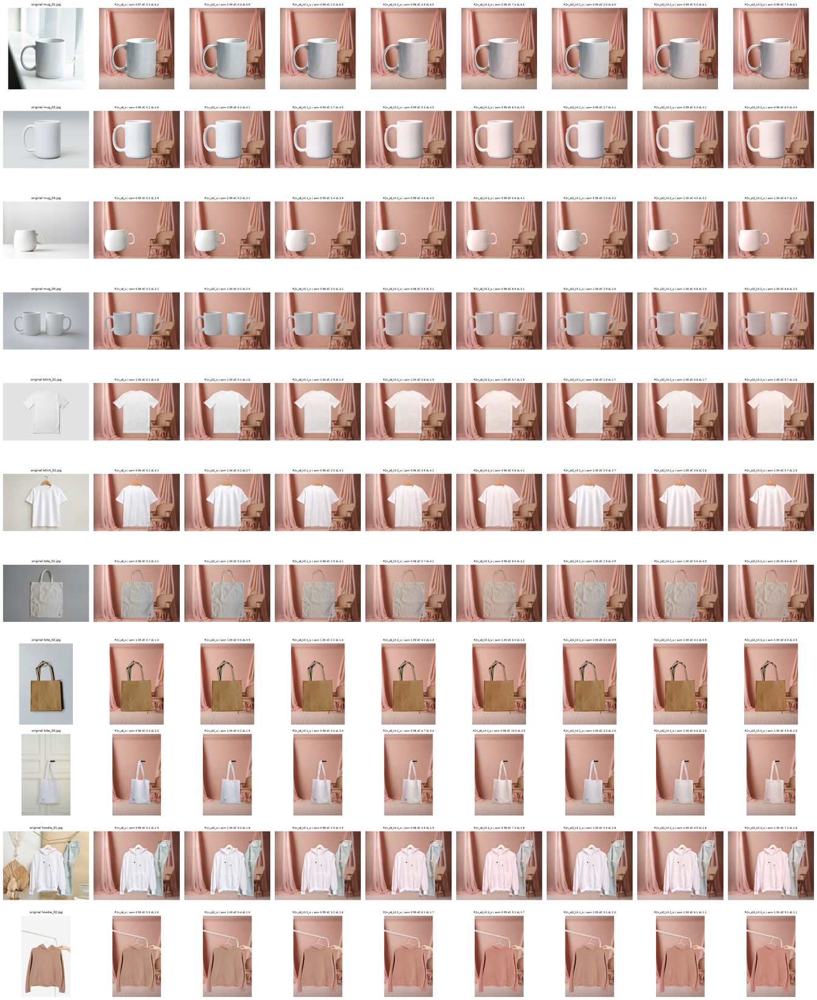

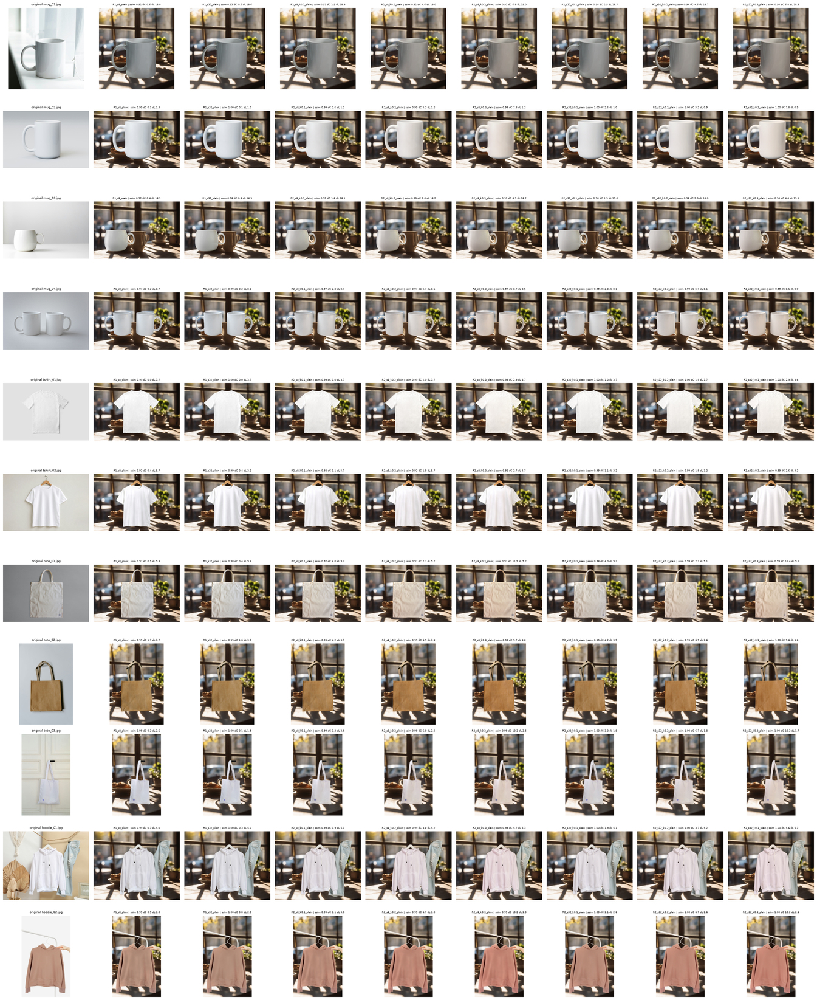

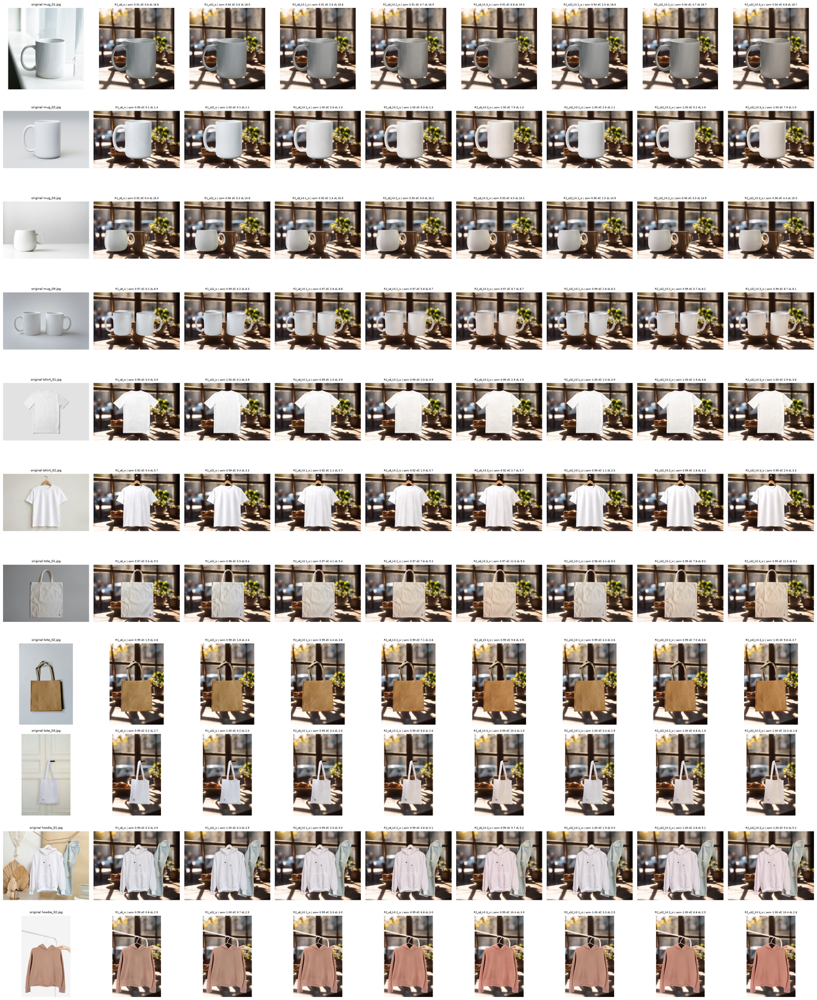

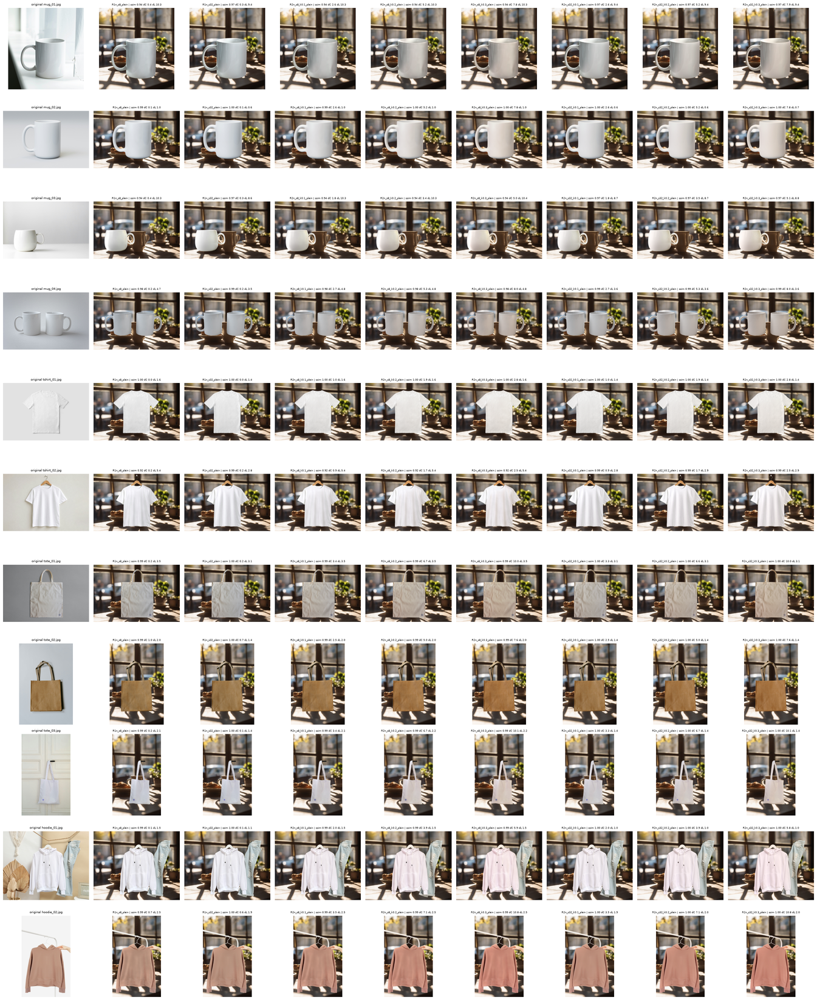

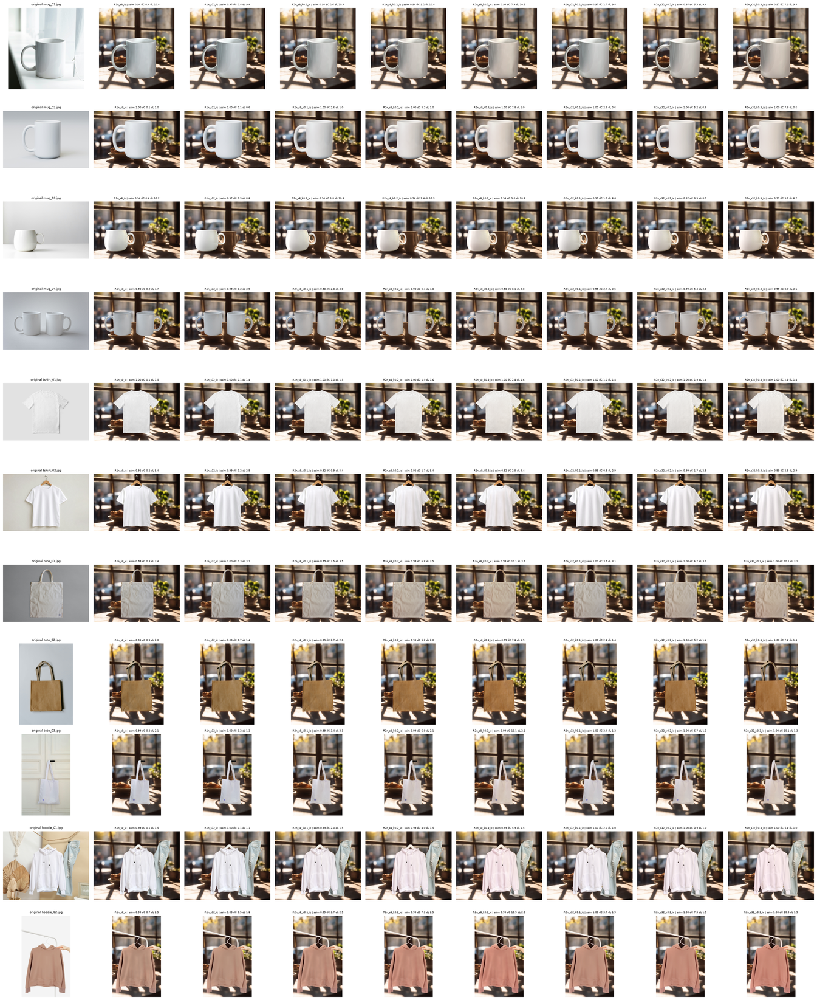

In [5]:
COLORS = {'D': '#9D755D', 'R0': '#BAB0AC', 'R1': '#4C78A8', 'R2': '#F58518', 'R1n': '#72B7B2', 'R2n': '#E45756', 'Y': '#54A24B'}


def color_of(m):
    return COLORS['D'] if m.startswith('D') else COLORS[m.split('_')[0]]


fig, axes = plt.subplots(4, 1, figsize=(20, 16))
x = np.arange(len(ORDER))
for ax, col, title in zip(axes, ['prod_ssim', 'prod_dC', 'prod_dL', 'scene_sim'],
                          ['goods structure kept (SSIM in mask, higher = kept)', 'goods color change (Lab dC in mask, lower = kept)',
                           'goods lighting change (Lab |dL| in mask)', 'scene similarity (CLIP)']):
    ax.bar(x, summ[(col, 'mean')], yerr=summ[(col, 'std')].fillna(0), capsize=2, color=[color_of(m) for m in ORDER])
    ax.set_xticks(x, ORDER, rotation=40, ha='right', fontsize=8)
    ax.set_title(f'{title} (mean ± std)', fontsize=10)
axes[0].set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(OUT_DIR / 'r_scores.png', dpi=80)
plt.show()

# 색 유지(가로) vs 조명 반영(세로): 왼쪽 위로 갈수록 "색은 그대로, 조명은 바뀜"
fig, ax = plt.subplots(figsize=(8, 6))
for m in ORDER:
    ax.scatter(summ.loc[m, ('prod_dC', 'mean')], summ.loc[m, ('prod_dL', 'mean')], color=color_of(m), s=40)
    ax.annotate(m, (summ.loc[m, ('prod_dC', 'mean')], summ.loc[m, ('prod_dL', 'mean')]), fontsize=7, xytext=(3, 3),
                textcoords='offset points')
ax.set_xlabel('goods color change dC (lower = color kept)')
ax.set_ylabel('goods lighting change |dL|')
ax.set_title('color kept vs lighting applied (mean per method)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'r_color_vs_light.png', dpi=80)
plt.show()


def show(path, method, name, sc):
    goods, _, _, _ = inputs(name, sc)
    im = Image.open(path).convert('RGB')
    return center_crop(im, goods.shape[1], goods.shape[0]) if method == 'D1' else im


def grid(sc, cols, tag):
    names = GOODS.file.tolist()
    fig, axes = plt.subplots(len(names), len(cols) + 1, figsize=(3.0 * (len(cols) + 1), 3.0 * len(names)), squeeze=False)
    for i, name in enumerate(names):
        goods, _, _, _ = inputs(name, sc)
        axes[i, 0].imshow(goods)
        axes[i, 0].set_title(f'original {name}', fontsize=7)
        for j, m in enumerate(cols):
            r = ds[(ds.goods == name) & (ds.scene == sc) & (ds.method == m)]
            if len(r):
                r = r.iloc[0]
                axes[i, j + 1].imshow(show((D_DIR if r.src == '15' else OUT_DIR) / r.file, m, name, sc))
                axes[i, j + 1].set_title(f'{m} | ssim {r.prod_ssim:.2f} dC {r.prod_dC:.1f} dL {r.prod_dL:.1f}', fontsize=6)
        for ax in axes[i]:
            ax.axis('off')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'r_grid_{sc}{tag}.png', dpi=50)
    plt.show()


MAIN = [m for m in ['D1', 'D2', 'R0', 'R1_s32_plain', 'R1_s32_ic', 'R1n_s8_plain', 'R1n_s32_plain', 'R1n_s8_ic', 'R1n_s32_ic', 'Y']
        if m in ORDER]
for sc in SCENES:
    grid(sc, MAIN, '')
# R2(색 비율) 비교: 식(그대로 / 평균 밝기 유지)·배경별로 R1과 함께
for sc in SCENES:
    for pre, tag in [(('R1_', 'R2_'), ''), (('R1n_', 'R2n_'), '_norm')]:
        for b in BGS:
            grid(sc, [m for m in ORDER if m.startswith(pre) and m.endswith(b)], f'{tag}_{b}')